# GTF / 03: small account and leverage for the GTF 02 trade (reported, not gated)

Question (Iván, 2026-11-08): with **$180** and **500:1** leverage, what does the equity curve of the long 09:25 → 09:55 + short 09:55 → 10:30 trade look like, and how many losing trades in a row wipe the account?

**Status of the trade.** GTF 02 is `PENDING_HOLDOUT`: gates pass on 2016–2025, which are exploratory, and fail G2/G3 on 2010–2015. The 2026 holdout has not been opened. Everything here sizes a trade whose edge is not confirmed; this notebook has no gates and cannot change that verdict.

**Model.**
- Each gotobi day: buy at 09:25 JST, sell at 09:55 and reverse into the short, which is stopped at +12 pips or bought back at 10:30. P&L in pips after spread from the tick backtest.
- Commission $35 per $1M per side, on each leg.
- Notional = equity × leverage, rounded down to 1,000 units (`full`), or fixed at $180 × leverage (`fixed`).
- Margin = notional / leverage. The broker liquidates when equity falls below 50% of margin. The open loss inside each leg is approximated from the minute mid path, so intra-minute spikes are missed and stop-outs are understated.
- An account is treated as wiped below $20.

**Regulation.** EU retail FX is capped at 30:1 on major pairs (ESMA; Dukascopy Europe 1:30). 500:1 is only offered by non-EU entities, with weaker client protection.

In [1]:
import os, sys, json
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import gotobi as G

cfg = G.GTFConfig()
E0, FLOOR, C35 = 180.0, 20.0, cfg.commission_usd_per_m
LEVERAGES = [10, 30, 100, 200, 500]
WINDOWS = {"2010-2015": G.WINDOWS["INDEPENDENT"], "2016-2025": G.WINDOWS["REPLICATION"],
           "2010-2025": (G.WINDOWS["INDEPENDENT"][0], G.WINDOWS["REPLICATION"][1])}
OUT = Path.cwd() / "03"; OUT.mkdir(exist_ok=True)
SHORT = G.grid_key(cfg.entry_min, cfg.exit_min, cfg.stop_pips)
LONG, LONG_PX = f"long_e{cfg.long_entry_min}", f"long_price_e{cfg.long_entry_min}"
pd.set_option("display.width", 200, "display.max_columns", 40)

## 1. Trades

In [2]:
days = G.build_day_outcomes(G.WINDOWS["INDEPENDENT"][0], G.WINDOWS["REPLICATION"][1], cfg, root=G.dukascopy_root(), n_jobs=4)
g = days[(days["day_type"] == "gotobi") & days[LONG].notna() & days[SHORT].notna()].copy()
g = g.join(G.adverse_excursions(g, cfg.long_entry_min, cfg.entry_min, cfg.exit_min, cfg.stop_pips))
trades = pd.DataFrame({"long": g[LONG], "short": g[SHORT], "long_px": g[LONG_PX], "short_px": g["entry_price"],
                       "mae_long": g["mae_long"], "mae_short": g["mae_short"]})
trades.index = pd.to_datetime(g["date"])
trades = trades.dropna().sort_index()
trades["net_pips"] = (trades["long"] + trades["short"] - G.commission_pips(trades["long_px"], C35)
                      - G.commission_pips(trades["short_px"], C35))
print(len(trades), "trades;", trades.index[0].date(), "->", trades.index[-1].date())
display(trades[["net_pips", "mae_long", "mae_short"]].describe().round(2))

1115 trades; 2010-01-05 -> 2025-12-30


,net_pips,mae_long,mae_short
count,1115.00,1115.00,1115.00
mean,1.81,6.07,4.64
std,15.44,7.14,4.20
min,-69.73,0.00,0.00
25%,-6.53,1.60,0.95
50%,1.23,3.95,3.00
75%,8.87,7.90,8.10
max,148.53,88.55,12.00


## 2. How much leverage the edge can carry (Kelly)

With position size *x* = fraction of equity per pip, expected log growth per trade ≈ *x·μ − x²σ²/2*, maximised at *x\* = μ/σ²* (μ, σ: mean and standard deviation of net pips per trade). Leverage = *x · price / 0.01*. Above **2× Kelly** expected log growth is negative: the account shrinks towards zero even with a positive mean.

In [3]:
px = trades["long_px"].mean()
k_rows = []
for w, (a, b) in WINDOWS.items():
    x = trades.loc[str(a):str(b), "net_pips"]
    mu, sd = x.mean(), x.std()
    kelly = mu / sd**2 if mu > 0 else 0.0
    k_rows.append({"window": w, "trades": len(x), "mean_net_pips": mu, "sd_pips": sd,
                   "full_kelly_leverage": kelly * px / G.PIP, "half_kelly_leverage": 0.5 * kelly * px / G.PIP})
for L in LEVERAGES:
    for r in k_rows:
        xL = L * G.PIP / px                                     # equity fraction per pip at leverage L
        r[f"log_growth_per_trade_{L}x"] = xL * r["mean_net_pips"] - 0.5 * (xL * r["sd_pips"]) ** 2
kelly_tab = pd.DataFrame(k_rows).set_index("window")
display(kelly_tab.T.round(4)); kelly_tab.to_csv(OUT / "03_kelly.csv")

window,2010-2015,2016-2025,2010-2025
trades,414.0000,701.0000,1115.0000
mean_net_pips,0.2108,2.7557,1.8107
sd_pips,11.9107,17.1200,15.4363
full_kelly_leverage,16.7572,106.0486,85.7152
half_kelly_leverage,8.3786,53.0243,42.8576
log_growth_per_trade_10x,0.0001,0.0023,0.0015
log_growth_per_trade_30x,0.0001,0.0063,0.0040
log_growth_per_trade_100x,-0.0037,0.0129,0.0067
log_growth_per_trade_200x,-0.0186,0.0028,-0.0054
log_growth_per_trade_500x,-0.1300,-0.1658,-0.1538


## 3. Equity curves from $180

The actual trade sequence, by leverage and sizing mode. Log scale.

final_equity                        max_drawdown                      stopouts                    
window            2010-2015  2010-2025   2016-2025    2010-2015 2010-2025 2016-2025 2010-2015 2010-2025 2016-2025
mode  leverage                                                                                                   
fixed 10             193.12     350.93      337.80        -0.12     -0.12     -0.04         0         0         0
      30             243.00    1032.01      969.02        -0.36     -0.36     -0.15         0         0         0
      100            344.77    3185.22     3016.27        -0.62     -0.62     -0.32         0         0         0
      200            122.32    5514.57     5838.06        -0.92     -0.92     -0.41         1         2         0
      500              1.77       1.77        1.00        -0.98     -0.98     -1.00         6         6        23
full  10             188.90     641.02      629.73        -0.19     -0.19     -0.11         0         0         0
      30             211.71   12404.52    10600.75        -0.56     -0.56     -0.34         0         0         0
      100             35.70  415484.40  2330283.91        -0.98     -0.98     -0.85         1         2         1
      200              2.50       2.50   440857.50        -1.00     -1.00     -0.99         5         5        21
      500              1.77       1.77        1.53        -0.98     -0.98     -0.99         6         6        23

,window,mode,leverage,first_below_20,trades_before_wipe
3,2010-2015,full,200,2010-02-15,8.0
4,2010-2015,full,500,2010-02-05,6.0
8,2010-2015,fixed,200,2010-02-15,8.0
9,2010-2015,fixed,500,2010-02-05,6.0
14,2016-2025,full,500,2016-02-19,9.0
19,2016-2025,fixed,500,2016-02-19,9.0
23,2010-2025,full,200,2010-02-15,8.0
24,2010-2025,full,500,2010-02-05,6.0
28,2010-2025,fixed,200,2010-02-15,8.0
29,2010-2025,fixed,500,2010-02-05,6.0


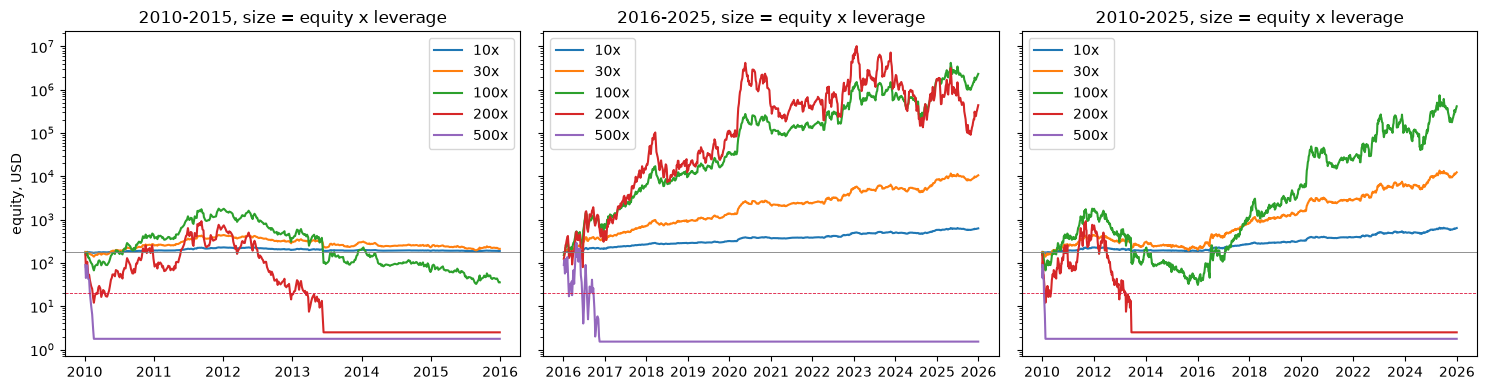

In [4]:
summary = []
curves = {}
for w, (a, b) in WINDOWS.items():
    tr = trades.loc[str(a):str(b)]
    for mode in ("full", "fixed"):
        for L in LEVERAGES:
            acc = G.simulate_account(tr, E0, L, mode, C35, 0.5)
            curves[(w, mode, L)] = acc["equity"]
            below = acc.index[acc["equity"] < FLOOR]
            summary.append({"window": w, "mode": mode, "leverage": L, "final_equity": acc["equity"].iloc[-1],
                            "max_drawdown": acc["drawdown"].min(), "stopouts": int(acc["event"].str.startswith("stopout").sum()),
                            "first_below_20": below[0].date() if len(below) else None,
                            "trades_before_wipe": int(np.argmax(acc["equity"].to_numpy() < FLOOR)) if len(below) else None})
summ = pd.DataFrame(summary)
display(summ.pivot_table(index=["mode", "leverage"], columns="window", values=["final_equity", "max_drawdown", "stopouts"], aggfunc="first").round(2))
display(summ[summ["first_below_20"].notna()][["window", "mode", "leverage", "first_below_20", "trades_before_wipe"]])
summ.to_csv(OUT / "03_equity_summary.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, w in zip(axes, WINDOWS):
    for L in LEVERAGES:
        ax.plot(curves[(w, "full", L)].clip(lower=0.1), label=f"{L}x")
    ax.axhline(E0, color="grey", lw=0.6); ax.axhline(FLOOR, color="crimson", lw=0.6, ls="--")
    ax.set_yscale("log"); ax.set_title(f"{w}, size = equity x leverage"); ax.legend()
axes[0].set_ylabel("equity, USD")
plt.tight_layout(); plt.savefig(OUT / "03_equity_full.png", dpi=120); plt.show()

## 4. Losing streaks

Longest run of losing days in the data, and how many consecutive losses take $180 below $20 at each leverage (size = equity × leverage), for two loss sizes: the average losing day and a 12-pip short stop with a flat long leg. Stop-out is not applied here: this is the arithmetic of the losses alone.

In [5]:
lose = trades.loc[trades["net_pips"] < 0, "net_pips"]
streaks = {w: G.longest_losing_streak(trades.loc[str(a):str(b), "net_pips"]) for w, (a, b) in WINDOWS.items()}
print("longest losing streak:", streaks)
print(f"average losing day: {lose.mean():.2f} pips net; 10% of losing days are worse than {lose.quantile(0.1):.1f} pips")

rows = []
for L in LEVERAGES:
    for name, loss in [("average losing day", -lose.mean()), ("12-pip stop, flat long", 12.0 + 2 * G.commission_pips(px, C35))]:
        frac = L * G.PIP / px * loss                                   # equity fraction lost per losing day
        n = np.inf if frac <= 0 else (1 if frac >= 1 - FLOOR / E0 else int(np.ceil(np.log(FLOOR / E0) / np.log(1 - frac))))
        rows.append({"leverage": L, "loss": name, "loss_pips": loss, "equity_lost_per_loss": min(frac, 1.0), "losses_to_below_20": n})
streak_tab = pd.DataFrame(rows).pivot(index="leverage", columns="loss", values=["equity_lost_per_loss", "losses_to_below_20"])
display(streak_tab.round(3)); streak_tab.to_csv(OUT / "03_losses_to_wipe.csv")

longest losing streak: {'2010-2015': 7, '2016-2025': 11, '2010-2025': 11}
average losing day: -10.04 pips net; 10% of losing days are worse than -20.5 pips


equity_lost_per_loss                        losses_to_below_20                   
loss     12-pip stop, flat long average losing day 12-pip stop, flat long average losing day
leverage                                                                                    
10                        0.012              0.009                  182.0              246.0
30                        0.036              0.027                   60.0               82.0
100                       0.120              0.089                   18.0               24.0
200                       0.241              0.178                    8.0               12.0
500                       0.602              0.445                    3.0                4.0

## 5. One-year outlook by resampling

5,000 random years of 70 gotobi days drawn with replacement from each window's trades (MAE kept with its day), size = equity × leverage. Probability of ending below $20 and the median ending equity. Resampling assumes the window's trade distribution continues; for 2016–2025 that assumption is exactly what the holdout has not yet tested.

In [6]:
N_SIM, N_TR = 5_000, 70
mc = []
for w in ("2010-2015", "2016-2025"):
    a, b = WINDOWS[w]
    pool = trades.loc[str(a):str(b)].reset_index(drop=True)
    for L in LEVERAGES:
        ends = G.simulate_final_equity(pool, E0, L, N_SIM, N_TR, cfg.seed + L, "full", C35, 0.5)
        mc.append({"window": w, "leverage": L, "p_below_20": float((ends < FLOOR).mean()),
                   "p_loss": float((ends < E0).mean()), "median_end": float(np.median(ends)),
                   "p05_end": float(np.percentile(ends, 5)), "p95_end": float(np.percentile(ends, 95))})
mc = pd.DataFrame(mc)
display(mc.pivot(index="leverage", columns="window").round(3)); mc.to_csv(OUT / "03_one_year_resampling.csv", index=False)

p_below_20              p_loss           median_end             p05_end             p95_end           
window    2010-2015 2016-2025 2010-2015 2016-2025  2010-2015 2016-2025 2010-2015 2016-2025 2010-2015  2016-2025
leverage                                                                                                       
10            0.000     0.000     0.416     0.079    182.275   194.893   164.844   177.677   198.729    226.993
30            0.000     0.000     0.467     0.095    184.562   264.471   116.322   162.389   300.903    447.349
100           0.024     0.002     0.609     0.190    135.415   458.370    26.972    78.627   727.305   2826.359
200           0.326     0.077     0.771     0.366     45.354   367.480     4.247    12.487  1065.157  11657.164
500           0.914     0.582     0.970     0.748      1.410     6.000     1.000     1.000    59.000  11998.971

In [7]:
res = {"E0": E0, "floor": FLOOR, "kelly": kelly_tab.round(4).to_dict(orient="index"), "longest_losing_streak": streaks,
       "equity": summ.to_dict(orient="records"), "one_year": mc.to_dict(orient="records"),
       "note": "Sizing only. GTF 02 is PENDING_HOLDOUT; nothing here is a verdict."}
(OUT / "summary.json").write_text(json.dumps(res, indent=2, default=str))
print("written", OUT / "summary.json")

written D:\Projects\equity_trading\notebooks\Gotobi_Tokyo_Fix\03\summary.json
